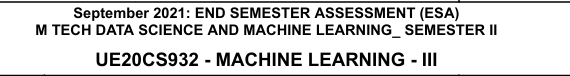

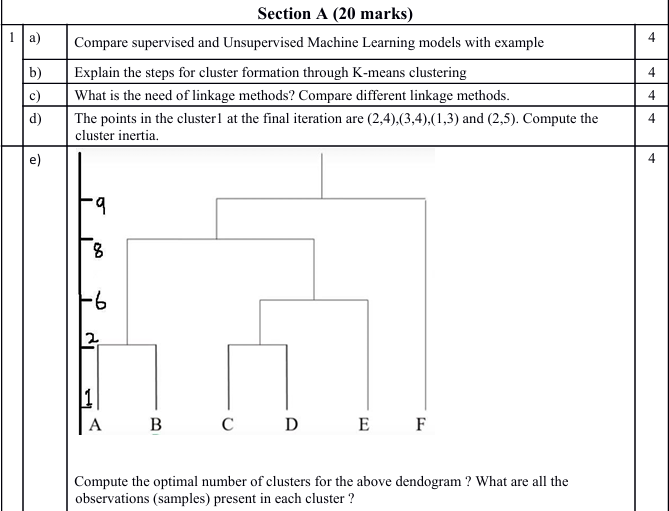/

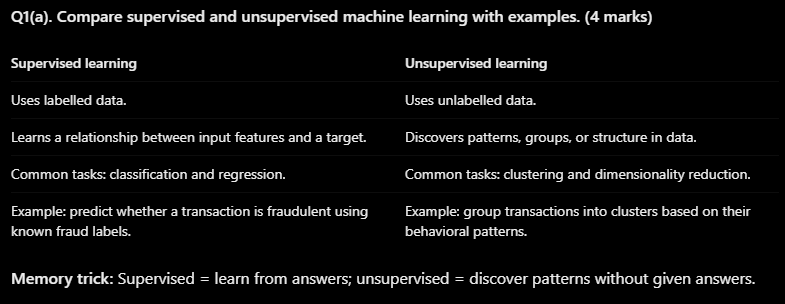  Also write algorithm names

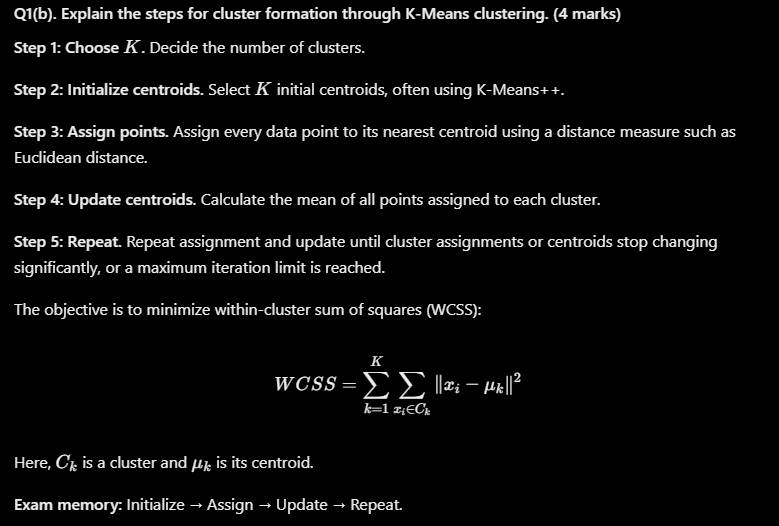

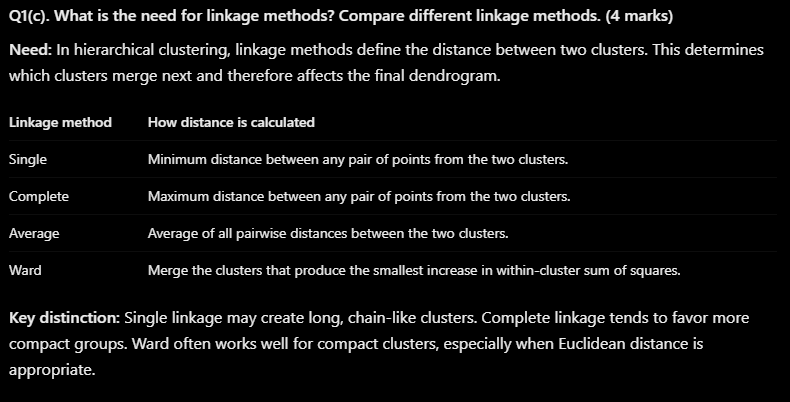

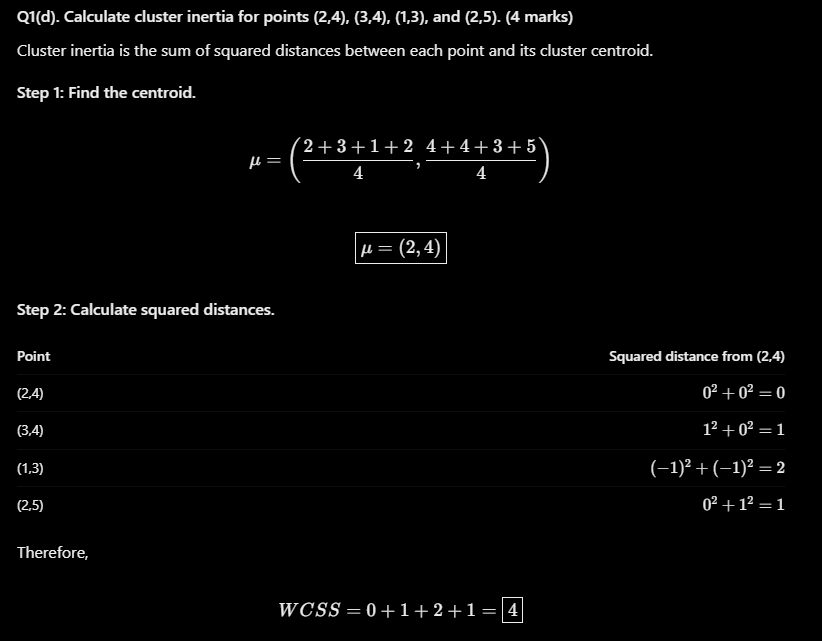

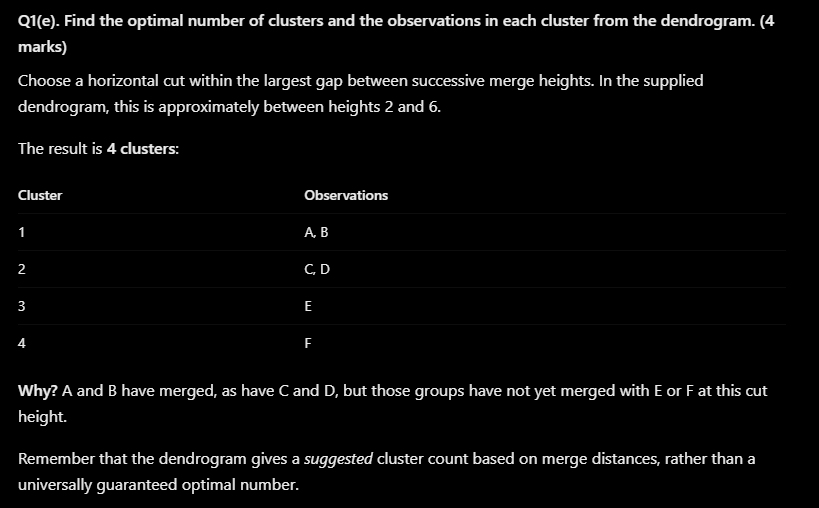

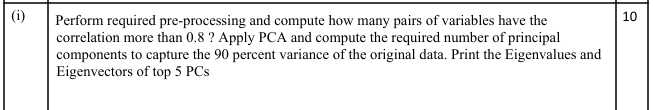

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [3]:
# Step 1 — Preprocess and count correlated pairs

#Load Data
df = pd.read_csv("cluster_data.csv")
print("Shape:",df.shape)

print("Missing:",df.isnull().sum().sum())

print("Duplicates:",df.duplicated().sum())

#if duplicates exist - drop them using df = df.drop_duplicates()

Shape: (10299, 563)
Missing: 0
Duplicates: 0


In [6]:
# Remove target and subject identifier for clustering
X = df.drop(columns=['Activity','subject/Participant'],errors="ignore")
# for dropping single column --> X = df.drop("column",axis=1)

# Handle missing values
X = X.fillna(X.median())

# Count pair correlation
corr = X.corr()
# if negative and positive side , use corr = X.corr().abs()

pairs = ((corr > 0.8).sum().sum() - len(corr)) // 2  # --> to avoid counting twice
print("Pairs with correlation GT 0.8:",pairs)

Pairs with correlation GT 0.8: 20672


In [7]:
# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [8]:
# Step 2 — Apply PCA and print the required values

pca = PCA(n_components=0.90)
X_pca90 = pca.fit_transform(X_scaled)

print("Components for 90% variance:",pca.n_components_)
print("Top 5 Eigen values:",pca.explained_variance_[:5])
print("Top 5 Eigen vectors:",pca.components_[:5])

Components for 90% variance: 65
Top 5 Eigen values: [284.66906046  35.0052311   15.10675009  13.76194237  10.59795807]
Top 5 Eigen vectors: [[ 0.00032202 -0.00265502 -0.00183102 ... -0.02322551  0.028696
   0.02622314]
 [ 0.01667862  0.00050924 -0.00496277 ...  0.0248285  -0.04036438
  -0.02188039]
 [-0.03345162  0.00185358  0.00901579 ...  0.0927247  -0.06636139
  -0.04427153]
 [-0.02166831 -0.00044926  0.00950881 ...  0.13336415 -0.11143218
  -0.14892314]
 [-0.00083394 -0.00998015 -0.00324271 ...  0.16400778 -0.12754761
  -0.08514572]]


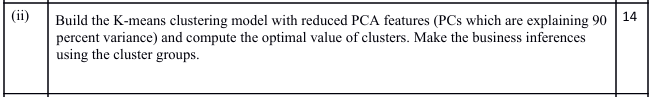

In [12]:
# Step 2 — Find a suitable K 

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):
    km = KMeans(n_clusters=k,random_state=42,n_init=10)
    labels = km.fit_predict(X_pca90)
    scores.append(silhouette_score(X_pca90,labels))

best_k = range(2,11)[np.argmax(scores)]
print("Best k:",best_k)

Best k: 2


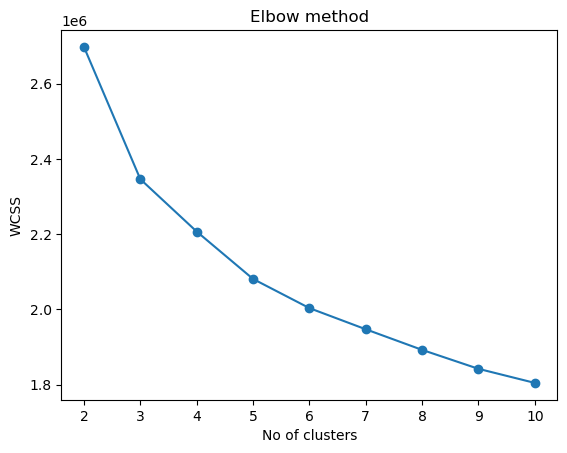

In [15]:
# Elbow plot
plt.plot(range(2,11),wcss,marker="o")
plt.xlabel("No of clusters")
plt.ylabel("WCSS")
plt.title("Elbow method")
plt.show()


How to interpret the plots:
- Elbow: look for the point after which adding more clusters reduces WCSS less substantially.
- Silhouette: a larger value usually indicates better separation and within-cluster cohesion.

In [ ]:
# Elbow plot gives 5 , but elbow method is subjective,
# Silhouette is highest at 2, hence k = 2

In [16]:
# Step 2: Fit final K-Means and inspect cluster characteristics.

km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels = km.fit_predict(X_pca90)

# Compare original sensor features after clustering
cluster_data = X.copy()
cluster_data["Cluster"] = labels

print(cluster_data.groupby("Cluster").mean().round(2))

         tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  \
Cluster                                                            
0                     0.28              -0.02              -0.11   
1                     0.27              -0.02              -0.11   

         tBodyAcc-std()-X  tBodyAcc-std()-Y  tBodyAcc-std()-Z  \
Cluster                                                         
0                   -0.98             -0.94             -0.94   
1                   -0.16              0.00             -0.22   

         tBodyAcc-mad()-X  tBodyAcc-mad()-Y  tBodyAcc-mad()-Z  \
Cluster                                                         
0                   -0.98             -0.94             -0.94   
1                   -0.22             -0.03             -0.22   

         tBodyAcc-max()-X  ...  fBodyBodyGyroJerkMag-meanFreq()  \
Cluster                    ...                                    
0                   -0.92  ...                             0.14   
1   

In [19]:
pd.crosstab(labels,df["Activity"])

Activity,LAYING,SITTING,STANDING,WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS
row_0,,,,,,
0,1932,1774,1906,0,0,8
1,12,3,0,1722,1406,1536



One cluster holds WALKING,WALKING_DOWNSTAIRS,WALKING_UPSTAIRS (Moving),
the other cluster holds Sitting,Standing,Laying (Not Moving).

Business use : Fitness tracking; Inactivity/Fall alerts for target/elderly people

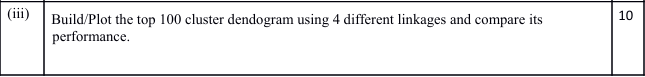

single cophenetic = 0.8101453137405764


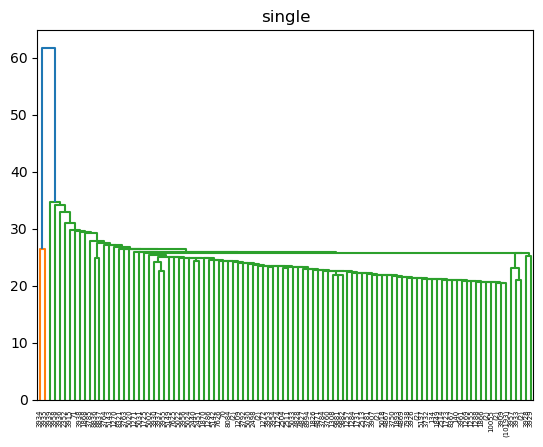

complete cophenetic = 0.7306080742636187


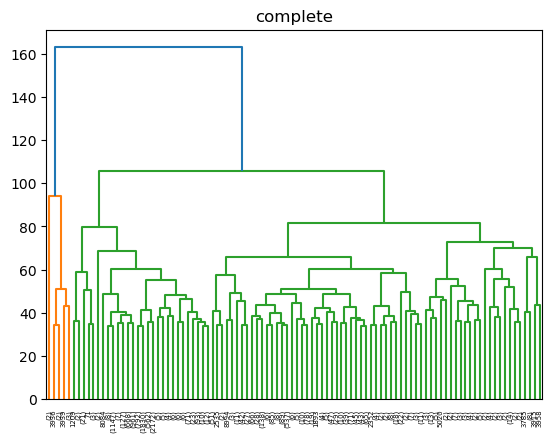

average cophenetic = 0.8591092069107692


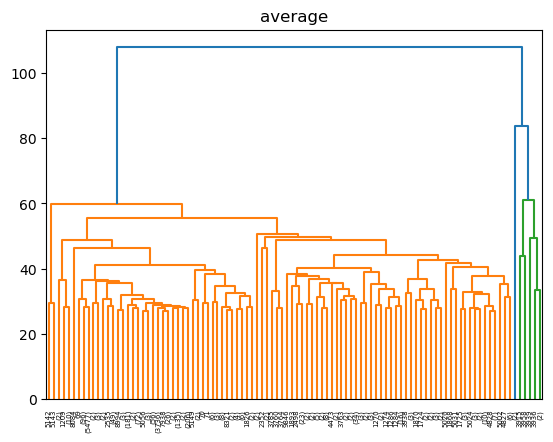

ward cophenetic = 0.6982374327522518


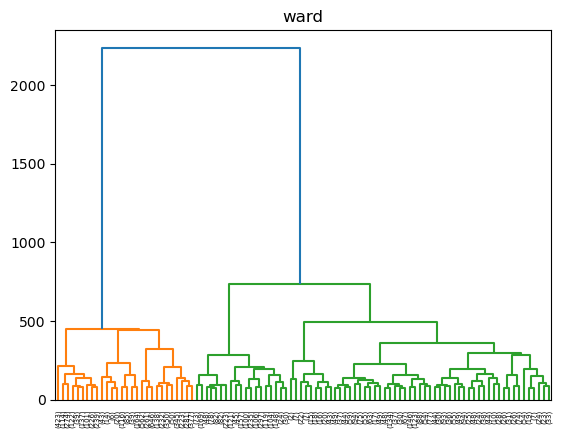

In [24]:
from scipy.cluster.hierarchy import linkage,dendrogram,cophenet
from scipy.spatial.distance import pdist

for method in ['single','complete','average','ward']:
    Z = linkage(X_pca90,method=method)
    c,d = cophenet(Z,pdist(X_pca90))
    print(method,'cophenetic =', c)
    dendrogram(Z,truncate_mode='lastp',p=100)
    plt.title(method)
    plt.show()

Inference = HIghest cophenetic = best dendogram,
Here, Average linkage.
We got compact,balanced clusters

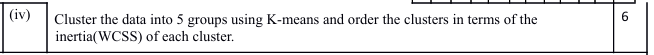

In [25]:
km = KMeans(n_clusters=5,n_init=10,random_state=42)
labels = km.fit_predict(X_pca90)

wcss = {}
for i in range(5):
    points = X_pca90[labels == i]
    wcss[i] = ((points - km.cluster_centers_[i]) ** 2).sum()

print(pd.Series(wcss).sort_values())

2    251431.745342
4    351726.905163
1    406707.441010
0    471972.647042
3    599265.899032
dtype: float64


The first cluster above in rank = 1 is most compact , the last one is most spread out

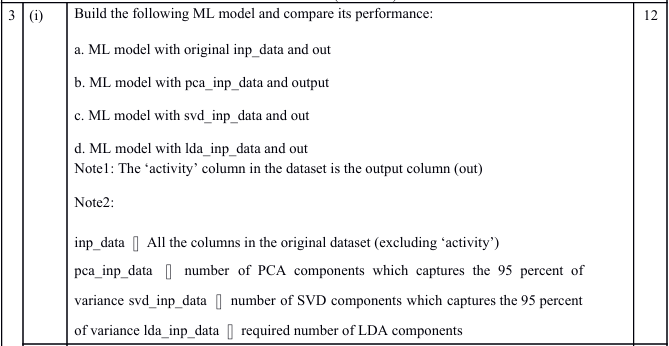

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [27]:
df = pd.read_csv("cluster_data.csv")

X = df.drop("Activity",axis=1)
y = df["Activity"]

X = X.fillna(X.median())

# Split first to avoid leakage
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

# Scale
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [28]:
results = {}

# 1.Original features
model = LogisticRegression(max_iter=1000)
model.fit(X_train,y_train)
results["Original"] = accuracy_score(y_test,model.predict(X_test))

# PCA - 95% features
pca = PCA(n_components=0.95)
A = pca.fit_transform(X_train)
B = pca.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(A,y_train)
results["PCA"] = accuracy_score(y_test,model.predict(B))

print(results)

{'Original': 0.9864077669902913, 'PCA': 0.9684466019417476}


In [29]:
# 3. SVD - approximately 95% variance
svd = TruncatedSVD(n_components=min(X_train.shape[1], X_train.shape[0]-1))
A = svd.fit_transform(X_train)
B = svd.transform(X_test)

n = np.argmax(np.cumsum(svd.explained_variance_ratio_) >= 0.95) + 1
A, B = A[:, :n], B[:, :n]

model = LogisticRegression(max_iter=1000)
model.fit(A, y_train)
results["SVD"] = accuracy_score(y_test, model.predict(B))

In [30]:
# 4. LDA - maximum classes minus one components

lda = LinearDiscriminantAnalysis(n_components=len(np.unique(y_train))-1)
A = lda.fit_transform(X_train,y_train)
B = lda.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(A,y_train)
results["LDA"] = accuracy_score(y_test,model.predict(B))

print(results)

{'Original': 0.9864077669902913, 'PCA': 0.9684466019417476, 'SVD': 0.9679611650485437, 'LDA': 0.9805825242718447}


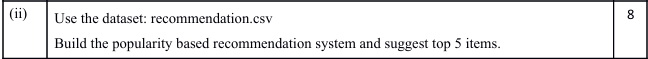

In [31]:
ratings = pd.read_csv("recommendation_mini.csv")
ratings.head()

,UserID,ItemID,Rating,Timestamp
0,905,470,1,889325071
1,697,1518,5,879835275
2,855,1687,5,875638677
3,950,1447,5,877420720
4,806,1170,4,879889337


In [32]:
popular = ratings.groupby("ItemID")["Rating"].count()
print(popular.sort_values(ascending=False).head(5))

ItemID
1650    497
1442    427
1519    427
1600    425
1412    417
Name: Rating, dtype: int64


This ranks products by the number of ratings received. It is a simple popularity measure; it is not personalized.

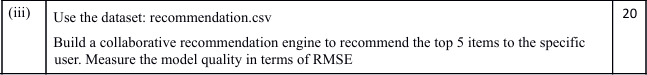

In [38]:
# pip install scikit-surprise

from surprise import Dataset,Reader,SVD,accuracy
from surprise.model_selection import train_test_split

ratings = pd.read_csv("recommendation_mini.csv")

reader = Reader(rating_scale=(1,5))
data = Dataset.load_from_df(
    ratings[["UserID","ItemID","Rating"]],reader
)

# Train/test split and RMSE
train,test = train_test_split(data,test_size=0.25,random_state=42)

model = SVD()
model.fit(train)

pred = model.test(test)
accuracy.rmse(pred)

# Train on full data for recommendations
model.fit(data.build_full_trainset())

user = ratings["UserID"].iloc[0]
rated = set(ratings[ratings.UserID == user]["ItemID"])
items = [i for i in ratings.ItemID.unique() if i not in rated]

predictions = [(i,model.predict(user,i).est) for i in items]
predictions.sort(key=lambda x:x[1],reverse=True)

print(predictions[:5])

RMSE: 0.9468
[(np.int64(1528), np.float64(4.861089452799894)), (np.int64(1650), np.float64(4.831367038933441)), (np.int64(1382), np.float64(4.701885570388052)), (np.int64(1699), np.float64(4.456756955003359)), (np.int64(1387), np.float64(4.44386619801803))]


Remember: Split → train SVD → RMSE → train on full ratings → predict unrated items → top five.

## Paper 4 — February 2025

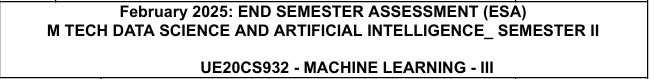

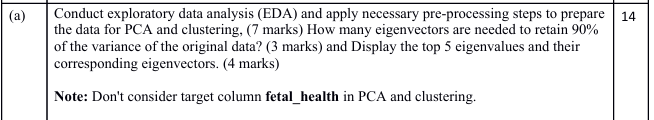

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.model_selection import train_test_split

In [40]:
df2 = pd.read_csv("fetal_health.csv")
df2.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


In [42]:
df2.isnull().sum().sum()

np.int64(0)

In [44]:
df2.duplicated().sum()

np.int64(13)

In [45]:
df2 = df2.drop_duplicates()

In [48]:
df2.fillna(df2.median())

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.000,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.000,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.000,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.000,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.000,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2121,140.0,0.000,0.000,0.007,0.000,0.0,0.0,79.0,0.2,25.0,...,137.0,177.0,4.0,0.0,153.0,150.0,152.0,2.0,0.0,2.0
2122,140.0,0.001,0.000,0.007,0.000,0.0,0.0,78.0,0.4,22.0,...,103.0,169.0,6.0,0.0,152.0,148.0,151.0,3.0,1.0,2.0
2123,140.0,0.001,0.000,0.007,0.000,0.0,0.0,79.0,0.4,20.0,...,103.0,170.0,5.0,0.0,153.0,148.0,152.0,4.0,1.0,2.0
2124,140.0,0.001,0.000,0.006,0.000,0.0,0.0,78.0,0.4,27.0,...,103.0,169.0,6.0,0.0,152.0,147.0,151.0,4.0,1.0,2.0


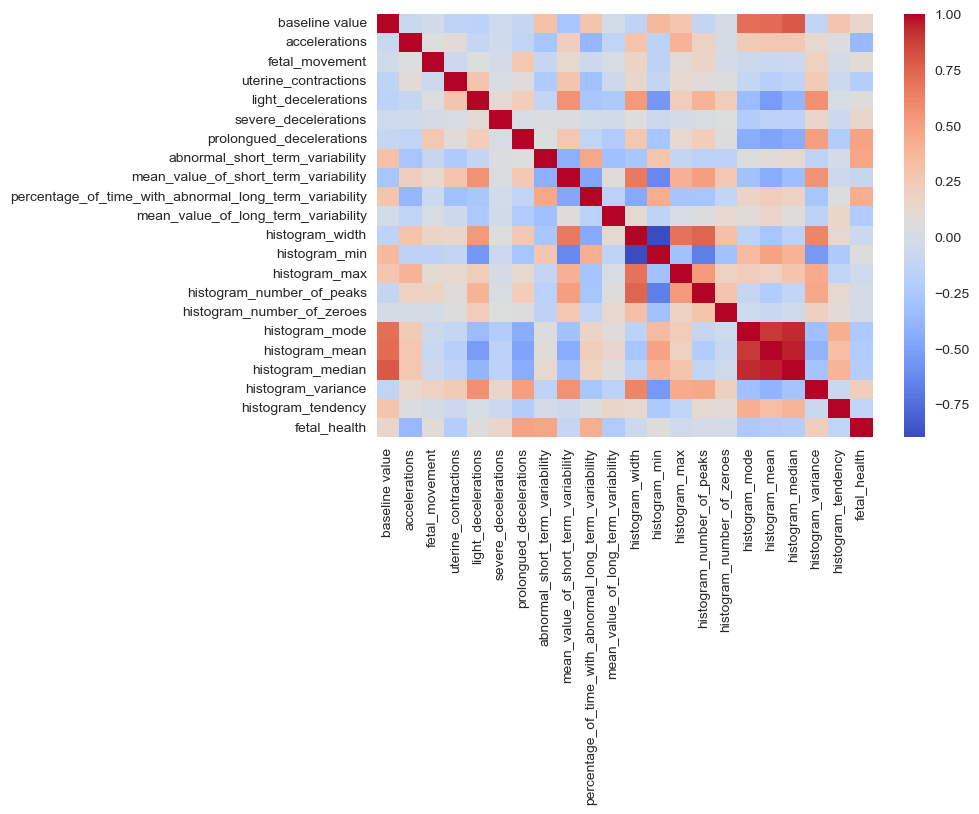

In [55]:
import seaborn as sns

sns.heatmap(df2.corr(),cmap="coolwarm")
plt.show()

In [49]:
X = df2.drop("fetal_health",axis=1)
y = df2["fetal_health"]

In [50]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [51]:
pca = PCA(n_components=0.90)
X_pca90 = pca.fit_transform(X_scaled)

print("No of comp for 90%:",pca.n_components_)
print("Top 5 eigen values:",pca.explained_variance_[:5])
print("Top 5 eigen vectors:",pca.components_[:5])

No of comp for 90%: 11
Top 5 eigen values: [6.06352156 3.5136936  1.81936586 1.49002892 1.21872996]
Top 5 eigen vectors: [[ 0.22360632 -0.04321047 -0.08073876 -0.12713937 -0.27868169 -0.05770597
  -0.20274952  0.14533512 -0.31627738  0.21709619  0.00803514 -0.31402344
   0.33280028 -0.13435381 -0.25126262 -0.12289625  0.26226416  0.30854816
   0.2757003  -0.2907375   0.06944483]
 [ 0.27653509  0.27776547  0.03814875  0.02444114  0.01885959 -0.07863112
  -0.11513331 -0.12495196  0.13534289 -0.14229105  0.09992222  0.28246099
  -0.14329098  0.37793717  0.23942251  0.12663656  0.36709495  0.32578342
   0.37598954  0.09840224  0.22783377]
 [ 0.34247255 -0.18766562  0.10278854 -0.13004048  0.19898902  0.07020612
   0.33668509  0.4910728  -0.07297112  0.31955488 -0.42797688  0.06582085
   0.02750763  0.18839092  0.11026901 -0.00333405  0.02450144 -0.02094437
   0.06722836  0.26570178 -0.03837096]
 [ 0.06182247 -0.44189074 -0.01135548 -0.28754378  0.08353677  0.03896793
  -0.09952779  0.08814

Remember: EDA → remove target → handle missing values → scale → PCA → print eigenvalues/eigenvectors.

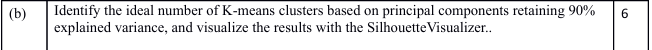

In [53]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import SilhouetteVisualizer

scores = []

for k in range(2,11):
    km = KMeans(n_clusters=k,n_init=10,random_state=42)
    labels = km.fit_predict(X_pca90)
    scores.append(silhouette_score(X_pca90,labels))

best_k = range(2,11)[np.argmax(scores)]
print("Best k:",best_k)

Best k: 2


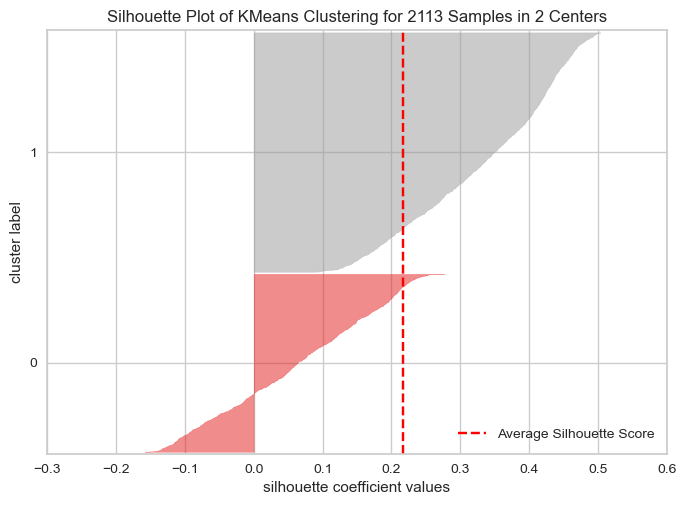

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 2113 Samples in 2 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [54]:
# Visualize selected K

model = KMeans(n_clusters=best_k,random_state=42,n_init=10)
visualizer = SilhouetteVisualizer(model)
visualizer.fit(X_pca90)
visualizer.show()

#### Extra : Apply K-Means and append cluster labels to standardized data. Find feature means per cluster.


In [57]:
km = KMeans(n_clusters=best_k,random_state=42,n_init=10)
labels = km.fit_predict(X_pca90)

data = pd.DataFrame(X_scaled,columns=X.columns)
data["cluster"] = labels

print(data.groupby("cluster").mean())

         baseline value  accelerations  fetal_movement  uterine_contractions  \
cluster                                                                        
0             -0.412304       0.176727        0.197815              0.264336   
1              0.306506      -0.131379       -0.147056             -0.196507   

         light_decelerations  severe_decelerations  prolongued_decelerations  \
cluster                                                                        
0                   0.720653              0.077553                  0.360835   
1                  -0.535733             -0.057653                 -0.268245   

         abnormal_short_term_variability  \
cluster                                    
0                              -0.307975   
1                               0.228948   

         mean_value_of_short_term_variability  \
cluster                                         
0                                    0.730136   
1                                 

In [58]:
pd.crosstab(labels,df2['fetal_health'])

fetal_health,1.0,2.0,3.0
row_0,,,
0,760,31,110
1,886,261,65


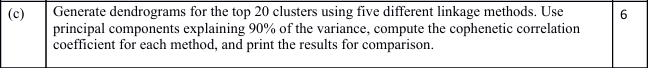

single CCC: 0.7190322483074483


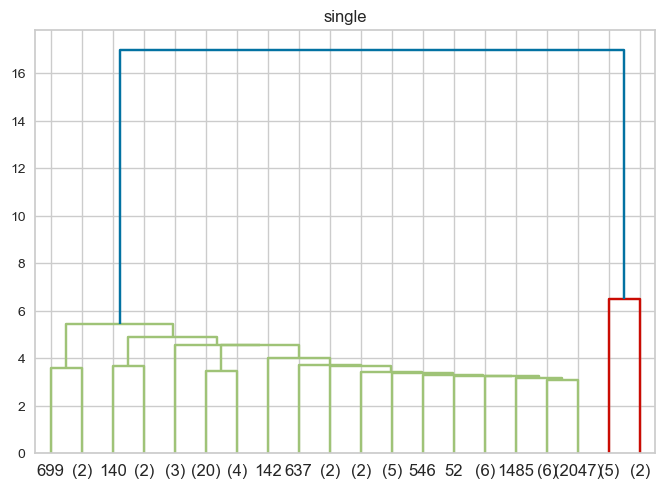

complete CCC: 0.54735408891465


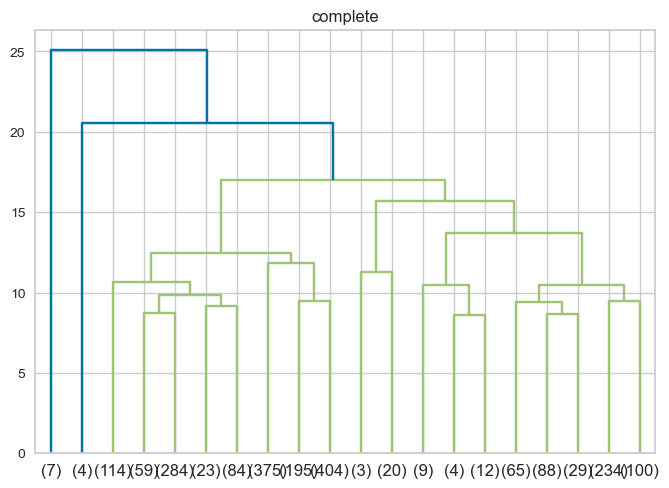

average CCC: 0.8154715759421043


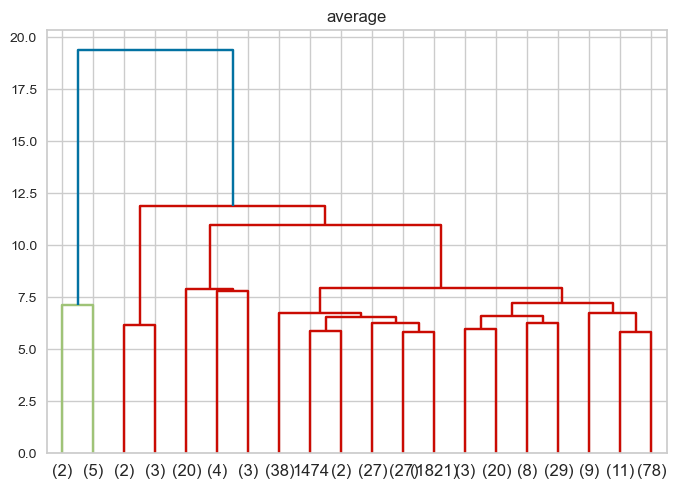

weighted CCC: 0.6940134462605694


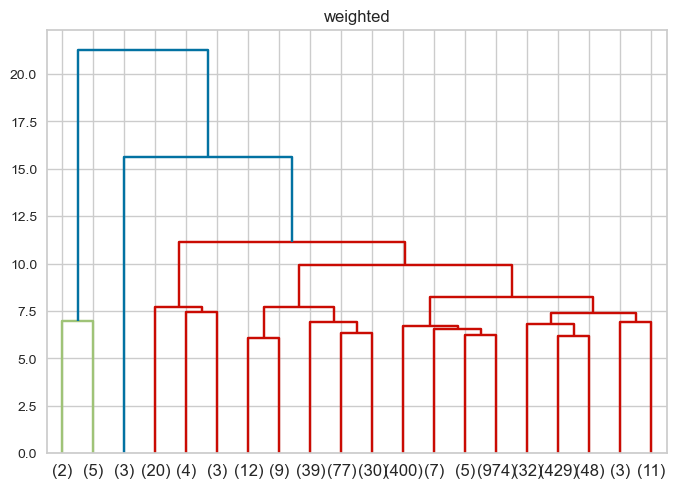

ward CCC: 0.3461766238052701


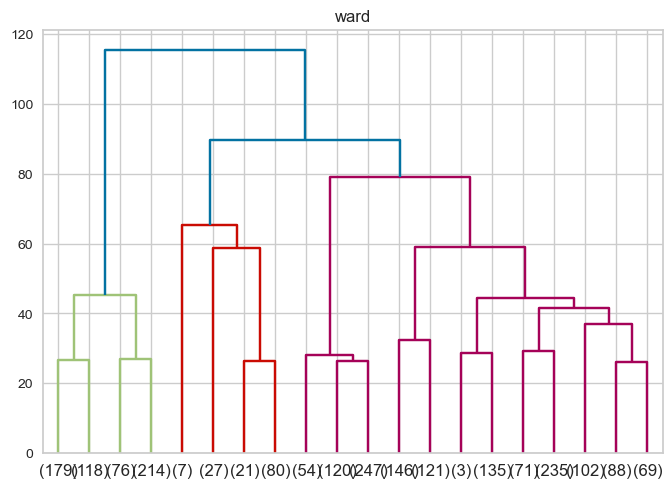

In [60]:
from scipy.cluster.hierarchy import linkage,dendrogram,cophenet
from scipy.spatial.distance import pdist

dist = pdist(X_pca90)
methods = ["single","complete","average","weighted","ward"]

for method in methods:
    Z = linkage(X_pca90,method=method)

    c,d = cophenet(Z,dist)
    print(method,"CCC:",c)

    dendrogram(Z,truncate_mode="lastp",p=20)
    plt.title(method)
    plt.show()

The linkage with the highest C preserves the original pairwise distances most faithfully among the methods tested. -- Average linkage here

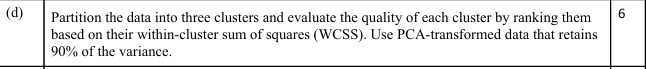

In [63]:
km = KMeans(n_clusters=3,random_state=42,n_init=10)
labels = km.fit_predict(X_pca90)

wcss = {}
for i in range(3):
    points = X_pca90[labels == i]
    wcss[i] = ((points - km.cluster_centers_[i]) ** 2).sum()

print(pd.Series(wcss).sort_values())

0     6539.748152
1     7545.116661
2    13911.421382
dtype: float64


##### Rank 1 ~ cluster 0 (WCSS ~ 6540 -- most compact)
##### Rank 2 ~ cluster 1 (WCSS ~ 7546)
##### Rank 3 ~ cluster 2 (WCSS ~ 13911 -- most spread out)

#### Lowest WCSS = Best quality cluster

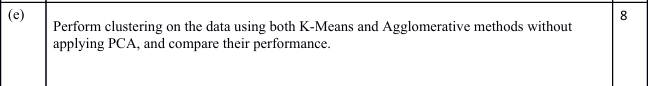

In [67]:
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Kmeans
km = KMeans(n_clusters=best_k,random_state=42,n_init=10)
labels1 = km.fit_predict(X_scaled)
s1 = silhouette_score(X_scaled,labels1)

# Agglomerative
agg = AgglomerativeClustering(n_clusters=best_k,linkage="average")
labels2 = agg.fit_predict(X_scaled)
s2 = silhouette_score(X_scaled,labels2)

print("K-Means:",s1)
print("Agglomerative:",s2)

K-Means: 0.2000664454004158
Agglomerative: 0.6969653029247902


##### Tried with linkage = ward and average , average linkage gave better results compared to ward.
0.2 vs 0.7
A higher score indicates better separation and cohesion according to this metric.

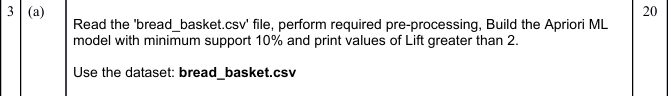

In [70]:
df3 = pd.read_csv("bread_basket.csv",header=None)
df3.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


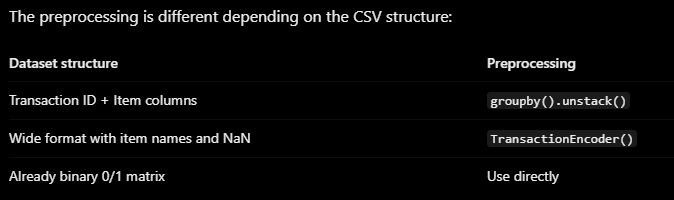

In [71]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori,association_rules

df3 = pd.read_csv("bread_basket.csv")

#Convert each row into a transaction
transactions = df3.apply(lambda x : x.dropna().to_list(),axis=1).tolist()

#Convert transactions into binary format
te = TransactionEncoder()
data = te.fit_transform(transactions)

basket = pd.DataFrame(data,columns=te.columns_)
basket.shape

(7500, 120)

In [74]:
#Apply Apriori
freq = apriori(basket,min_support=0.10,use_colnames=True)
print(freq)

# Generate association rules
rules = association_rules(freq,metric="lift",min_threshold=2)

# Display rules with Lift > 2
print(rules[rules["lift"]>2])

    support         itemsets
0  0.163867      (chocolate)
1  0.179733           (eggs)
2  0.170933   (french fries)
3  0.132000      (green tea)
4  0.129600           (milk)
5  0.238267  (mineral water)
6  0.174133      (spaghetti)
Empty DataFrame
Columns: [antecedents, consequents, antecedent support, consequent support, support, confidence, lift, representativity, leverage, conviction, zhangs_metric, jaccard, certainty, kulczynski]
Index: []


Write:
Apriori identified seven frequent individual items with support greater than or equal to 10%. However, no frequent item combinations were identified at this support threshold. Therefore, no association rules satisfying the specified conditions could be generated.

Apriori found individual popular items, but it did not find any combination of items that occurred together in at least 10% of transactions. That's why the association rules output is empty.

Support means the percentage of transactions containing an item or item combination.

For example:
- Chocolate: 0.163867 = 16.39% of transactions contained chocolate.
- Eggs: 0.179733 = 17.97% contained eggs.
- Mineral water: 0.238267 = 23.83% contained mineral water.
- Milk: 0.129600 = 12.96% contained milk.

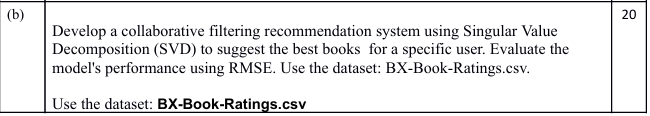

In [77]:
from surprise import Dataset,Reader,SVD,accuracy
from surprise.model_selection import train_test_split

ratings = pd.read_csv("BX-Book-Ratings.csv")
ratings.head()

,UserID,ItemID,Rating
0,276725,34545104,0
1,276726,155061224,5
2,276727,446520802,0
3,276729,52165615,3
4,276729,521795028,6


In [78]:
# Remove unrated interactions (rating 0)
ratings  = ratings[ratings["Rating"] > 0]

reader = Reader(rating_scale=(1,10))
data = Dataset.load_from_df(
    ratings[["UserID","ItemID","Rating"]],reader)

# Train/test and RMSE
train,test = train_test_split(data,test_size=0.25,random_state=42)

model = SVD()
model.fit(train)
accuracy.rmse(model.test(test))

# Fit on full data for recommendations
model.fit(data.build_full_trainset())

user = str(ratings["UserID"].iloc[0])
rated = set(ratings[ratings["UserID"] == user]["ItemID"])
items = [i for i in ratings["ItemID"].unique() if i not in rated]

predictions = [(i, model.predict(user, i).est) for i in items]
predictions.sort(key=lambda x: x[1], reverse=True)

print("Top 5 books:", predictions[:5])

RMSE: 1.7813
Top 5 books: [('440414121', np.float64(7.887915341759889)), ('2070404587', np.float64(7.803539006882653)), ('2266102621', np.float64(7.785194491900105)), ('2264036036', np.float64(7.783337962054168)), ('3100970616', np.float64(7.758934812635202))]


Write : The collaborative filtering model was evaluated using RMSE and obtained a value of 1.7813. The model then predicted ratings for unrated books and recommended the top five books based on their predicted ratings. The highest predicted rating was approximately 7.89.

Train SVD → Calculate RMSE → Predict ratings → Sort predictions → Recommend Top 5.

RMSE = 1.78
This means the model's prediction error is approximately 1.78 rating points on the rating scale used in your dataset.
Lower RMSE generally indicates better predictions.

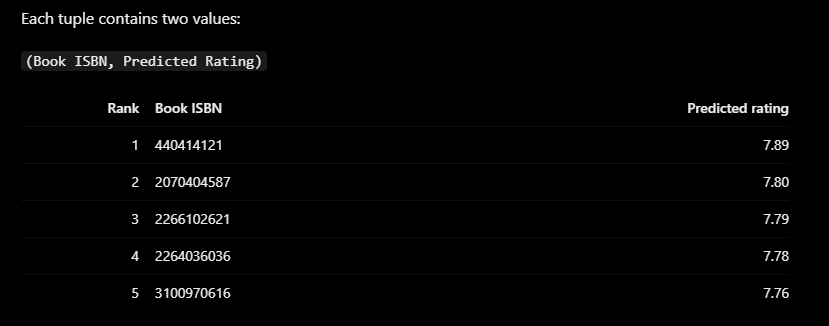

This means the model predicts a rating of approximately 7.89 for the book identified by ISBN 440414121.

The system ranks books according to their predicted ratings and returns the top five.